# Tarea 2: Modelo de ML sobre dataset de pokémon
>Por: Noam Jansson y Matías Solís

En esta tarea buscaremos continuar lo presentado en la tarea 1 sobre el dataset de los datos de pokémon hasta la $7^{ma}$ generación. Con el objetivo de implementar un modelo de machine learning, sobre los datos ya estudiados.

##¿Qué buscaremos hacer?

Nuestro objetivo será continuar la idea que presentamos la tarea pasada, donde nos propusimos analizar cuales eran las características más relevantes de un pokémon al momento del combate y que sean pokémon que valgan la pena entrenar. Bajo esta idea nos centraremos en ver que pokémon son fáciles de entrenar, según las características que vimos antes y otras que no consideramos.

Para ello nos dimos cuenta de una feature no considerada `experience_growth` que nos entrega cuanta experiencia es necesaria darle al pokémon para que alcance el nivel 100, que representa el esfuerzo que hay detrás para que un pokémon de su máximo potencial.

Así `experience_growth` será nuestro target.

Primero llamaremos a las librerías y funciones que necesitamos, además de añadir la tabla de datos (la que ya arreglamos la tarea pasada).

In [ ]:
import numpy as np
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import pandas as pd

In [ ]:
from sklearn import metrics
from sklearn.model_selection import cross_validate, KFold, StratifiedKFold, cross_val_predict, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, ExtraTreesRegressor
from sklearn.model_selection import train_test_split
from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.ensemble import RandomForestClassifier
from sklearn.base import clone

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
pk_bien = pd.read_csv("/content/drive/MyDrive/pokemon ML/pokemon_arreglado.csv")
pk_bien.head()

,against_bug,against_dark,against_dragon,against_electric,against_fairy,against_fight,against_fire,against_flying,against_ghost,against_grass,...,percentage_male,pokedex_number,sp_attack,sp_defense,speed,type1,type2,weight_kg,generation,is_legendary
0,1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,...,88.1,1,65,65,45,grass,poison,6.9,1,0
1,1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,...,88.1,2,80,80,60,grass,poison,13.0,1,0
2,1.0,1.0,1.0,0.5,0.5,0.5,2.0,2.0,1.0,0.25,...,88.1,3,100,100,80,grass,poison,100.0,1,0
3,0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,0.50,...,88.1,4,60,50,65,fire,NaN,8.5,1,0
4,0.5,1.0,1.0,1.0,0.5,1.0,0.5,1.0,1.0,0.50,...,88.1,5,80,65,80,fire,NaN,19.0,1,0


In [ ]:
#Definimos nuestra feature 'agains_total' implementado en la tarea 1
pk_bien['against_total'] = (
    pk_bien['against_bug'] +
    pk_bien['against_dark'] +
    pk_bien['against_dragon'] +
    pk_bien['against_electric'] +
    pk_bien['against_fairy'] +
    pk_bien['against_fight'] +
    pk_bien['against_fire'] +
    pk_bien['against_flying'] +
    pk_bien['against_ghost'] +
    pk_bien['against_grass'] +
    pk_bien['against_ground'] +
    pk_bien['against_ice'] +
    pk_bien['against_normal'] +
    pk_bien['against_poison'] +
    pk_bien['against_psychic'] +
    pk_bien['against_rock'] +
    pk_bien['against_steel'] +
    pk_bien['against_water']
)

##Target y Features:

Ahora definirimos como lo dijimos antes nuestro target `experience_growth` este es un valor numérico, lo que nos llevaría a un problema de regresión. Sin embargo esta variable tiene valores concisos que comparten muchas especies, no es tanto un valor continuo sino un conjunto de valores que toman varios pokémon. De esta manera nuestro problema pasa a ser uno de clasificación.

In [ ]:
print(pk_bien["experience_growth"].value_counts().sort_index())

experience_growth
600000      22
800000      56
1000000    335
1059860    202
1250000    172
1640000     14
Name: count, dtype: int64


In [ ]:
print("Tipos de crecimiento:", pk_bien["experience_growth"].nunique())
print("Valores:", sorted(pk_bien["experience_growth"].unique()))

Tipos de crecimiento: 6
Valores: [np.int64(600000), np.int64(800000), np.int64(1000000), np.int64(1059860), np.int64(1250000), np.int64(1640000)]


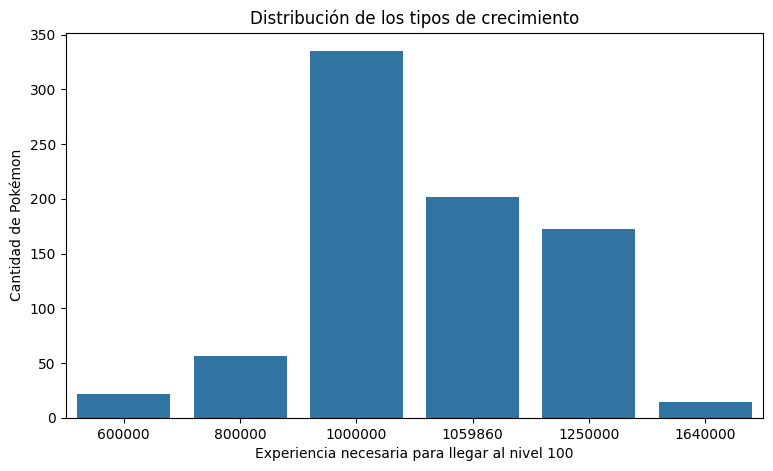

In [ ]:
#Hacemos un plot que ilustra de buena manera la distribución de estos valores fijos del target
plt.figure(figsize=(9, 5))

sns.countplot(
    data=pk_bien,
    x="experience_growth",
    order=sorted(pk_bien["experience_growth"].unique())
)

plt.xlabel("Experiencia necesaria para llegar al nivel 100")
plt.ylabel("Cantidad de Pokémon")
plt.title("Distribución de los tipos de crecimiento")
plt.show()

In [ ]:
#Separamos los valores numéricos en categorías más fáciles de entender
def clasificar_crecimiento(valor):
    if valor <= 800000:
        return 'Bajo'
    elif valor <= 1059860:
        return 'Medio'
    else:
        return 'Alto'

pk_bien['growth_category'] = pk_bien['experience_growth'].apply(
    clasificar_crecimiento
)

print(pk_bien['growth_category'].value_counts())

growth_category
Medio    537
Alto     186
Bajo      78
Name: count, dtype: int64


Hemos definido nuestro target que ahora es `growth_category` básicamente lo mismo de antes pero agrupando los valores del `experience_growth` en 3 categorías: **Bajo**, **Medio** y **Alto**. Donde **Bajo** representa a los pokémon que necesitan poca experiencia para alcanzar su máximo y así escala.

Para las features usaremos las mismas que en la Tarea pasada, vale decir: `is_legendary`, `base_happines`, `capture_rate`, `against_total`, y los stast. Además añadiremos `base_egg_steps`, `heigth_m` y `weight_kg`, ya que otros grupos mostraron trabajos y relaciones con estas fetures así que será bueno implementarlas al modelo (creditos a los otros grupos).

In [ ]:
features = [
    'hp',
    'attack',
    'defense',
    'sp_attack',
    'sp_defense',
    'speed',
    'is_legendary',
    'base_happiness',
    'capture_rate',
    'against_total',
    'base_egg_steps',
    'height_m',
    'weight_kg'
]

data = pk_bien[features + ['growth_category']].copy()

data['capture_rate'] = pd.to_numeric(
    data['capture_rate'],
    errors='coerce'
)

X = data[features]
y = data['growth_category']


In [ ]:
print("Cantidad de Pokémon por categoría:")
print(y.value_counts())

print("\nPorcentaje por categoría:")
print((y.value_counts(normalize=True) * 100).round(2))

Cantidad de Pokémon por categoría:
growth_category
Medio    537
Alto     186
Bajo      78
Name: count, dtype: int64

Porcentaje por categoría:
growth_category
Medio    67.04
Alto     23.22
Bajo      9.74
Name: proportion, dtype: float64


##Modelo de ML:
Ya tenemos nuestras features y targets, ahora nos falta elegir el modelo e implementarlo. El modelo que usaremos será de bagging y boosting, específicamente **Random Forest**, elejímos este modelo debido a que en clasificación es el mejor modelo que hemos visto, es muy estable a variabilidad y ruido, como tenemos tantas features es mucho más práctico y muy fácil de implementar, además evitamos el sobreajuste que haría un solo DT (árbol de desición). Así que gana en todos los sentidos, es práctico y presciso, y su principal incoveniente que es el costo computacional se ve drásticamente reducido, ya que no son demasiados datos.

In [ ]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=20
)

model = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(
        n_estimators=200,
        random_state=20,
        max_depth=11,
        min_samples_split=8,
        min_samples_leaf=5,
        class_weight='balanced',
        n_jobs=-1
    )
)

scores = cross_validate(
    model,
    X,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

print("Accuracy promedio:", scores['test_accuracy'].mean())
print("Desviación estándar:", scores['test_accuracy'].std())
print("F1 macro promedio:", scores['test_f1_macro'].mean())
print("F1 macro entrenamiento:", scores['train_f1_macro'].mean())

Accuracy promedio: 0.7840217391304349
Desviación estándar: 0.02453694506184222
F1 macro promedio: 0.6059029545226879
F1 macro entrenamiento: 0.9015261693714723


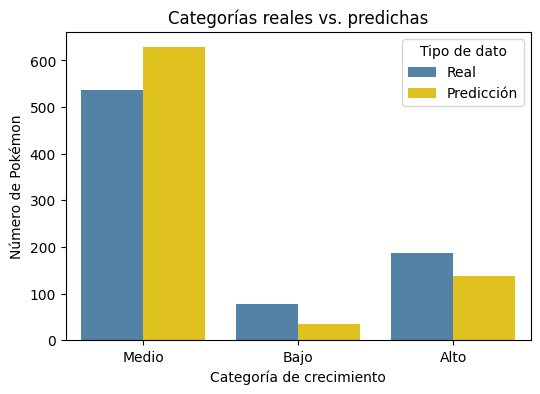

In [ ]:
ypred = cross_val_predict(model,X,y,cv=cv)

df_plot = pd.DataFrame({
    'Categoría': list(y) + list(ypred),
    'Conjunto': ['Real'] * len(y) + ['Predicción'] * len(ypred)})

plt.figure(figsize=(6,4))

sns.countplot(
    data=df_plot,
    x='Categoría',
    hue='Conjunto',
    palette=['steelblue', 'gold'])

plt.xlabel("Categoría de crecimiento")
plt.ylabel("Número de Pokémon")
plt.title("Categorías reales vs. predichas")
plt.legend(title="Tipo de dato")

plt.show()

##Evaluación del modelo:
Como métrica decidimos utilizar el accuracy, esto debido a que nos interesa nada más que como evalua el modelo en general. No buscamos mayor pureza ni completitud en especial, así que el accuracy con lo generalista que es nos sirve bastante, aún así usamos f1-score para igual tener la idea de como se comporta el modelo.

Es así que vemos que el accuracy promedio es bueno aproximadamente un 78%. En la gráfica podemos ver que al modelo le cuesta encontrar a los pokémon en categoría de **Bajo**, eso es lo que más falla.

##Un experimento:
Ahora que tenemos nuestro modelo, hagamos una pequeña modificación, veremos si la clasificación del modelo se ve drasticamente modificada al modificar que features tiene a su disposición. Random Forest es un conjunto de muchos DT que eligen que feature es la más conveniente usar para hacer el split. Esto hace que puedan pasar 2 cosas si hay una feature que es crucial y la sacamos, el modelo se desmorona, pero si sacamos las que son "ruido", es decir features que son parecidas a otras o que no son tan importantes el modelo casi ni se verá afectado.

Nosotros quitaremos `capture_ratio` y `base_happiness`, ya que consideramos que qe un pokémon sea amistoso y fácil de atrapar debería ser fácil de entrenar y crecería de manera más rápida. Por lo que implementaremos nuevamente el modelo pero sin esas features, esperando que el modelo tenga un peor rendimiento.

In [ ]:
features_new = [
    'hp',
    'attack',
    'defense',
    'sp_attack',
    'sp_defense',
    'speed',
    'is_legendary',
    'against_total',
    'base_egg_steps',
    'height_m',
    'weight_kg']
X_new = data[features_new]

model_new = make_pipeline(
    SimpleImputer(strategy='median'),
    RandomForestClassifier(
        n_estimators=200,
        random_state=20,
        max_depth=11,
        min_samples_split=8,
        min_samples_leaf=5,
        class_weight='balanced',
        n_jobs=-1
    )
)

scores_new = cross_validate(
    model_new,
    X_new,
    y,
    cv=cv,
    scoring=['accuracy', 'f1_macro'],
    return_train_score=True
)

print("Accuracy promedio:", scores_new['test_accuracy'].mean())
print("Desviación estándar:", scores_new['test_accuracy'].std())
print("F1 macro promedio:", scores_new['test_f1_macro'].mean())
print("F1 macro entrenamiento:", scores_new['train_f1_macro'].mean())

Accuracy promedio: 0.77902950310559
Desviación estándar: 0.022529785055614978
F1 macro promedio: 0.6054902682902974
F1 macro entrenamiento: 0.906096747663948


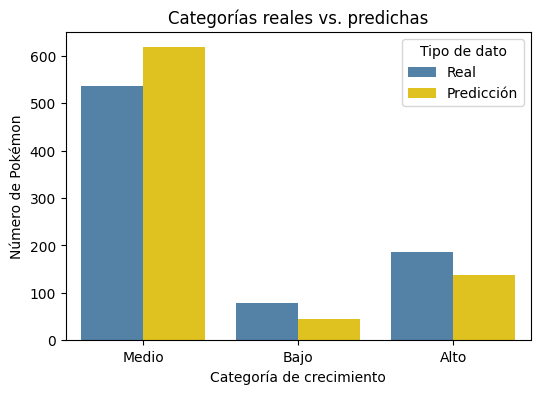

In [ ]:
ypred_new = cross_val_predict(model_new,X_new,y,cv=cv)

df_plot_new = pd.DataFrame({
    'Categoría': list(y) + list(ypred_new),
    'Conjunto': ['Real'] * len(y) + ['Predicción'] * len(ypred_new)})

plt.figure(figsize=(6,4))

sns.countplot(
    data=df_plot_new,
    x='Categoría',
    hue='Conjunto',
    palette=['steelblue', 'gold'])

plt.xlabel("Categoría de crecimiento")
plt.ylabel("Número de Pokémon")
plt.title("Categorías reales vs. predichas")
plt.legend(title="Tipo de dato")

plt.show()

Al parecer las features que escogimos no son las que más le importan al modelo. Es prácticamente igual al modelo antiguo, con un accuracy que empeoró un poco (bajó de 78,4% a 77.9%), pero nada muy relevante. Viendo los gráficos sufre del mismo problema, aparte de tener igual distribución. Veamos entonces qué features usaron más los modelos para hacer sus clasificaciones, utilizando feature_importances_

In [ ]:
#Features más importantes en el modelo viejo
importancias = []
for train_idx, test_idx in cv.split(X, y):
    model_cv = clone(model)
    model_cv.fit(X.iloc[train_idx], y.iloc[train_idx])
    rf = model_cv.named_steps['randomforestclassifier']
    importancias.append(rf.feature_importances_)
importancias = pd.DataFrame(
    importancias,
    columns=X.columns
)

print(importancias.mean().sort_values(ascending=False))

base_egg_steps    0.167524
weight_kg         0.105586
capture_rate      0.100172
attack            0.082887
height_m          0.068681
sp_defense        0.068097
speed             0.065214
hp                0.064653
sp_attack         0.064247
against_total     0.058647
defense           0.056632
base_happiness    0.053737
is_legendary      0.043921
dtype: float64


In [ ]:
#Features más importantes en el modelo nuevo
importancias_new = []
for train_idx, test_idx in cv.split(X_new, y):
    model_cv = clone(model_new)
    model_cv.fit(X_new.iloc[train_idx], y.iloc[train_idx])
    rf = model_cv.named_steps['randomforestclassifier']
    importancias_new.append(rf.feature_importances_)
importancias_new = pd.DataFrame(
    importancias_new,
    columns=X_new.columns
)

print(importancias_new.mean().sort_values(ascending=False))

base_egg_steps    0.193883
weight_kg         0.127079
attack            0.099058
height_m          0.080402
is_legendary      0.077173
sp_defense        0.075968
sp_attack         0.074339
speed             0.074175
hp                0.070777
defense           0.065489
against_total     0.061657
dtype: float64


Vemos que no hay ninguna variable que afecte de sobremanera al modelo o que sea muy crucial, al parecer `base_egg_steps` es la que más sirve para clasificar, pero igualmente se usa bastante poco o se reparte de manera más bien equitativa entre todas las features.

De igual forma queda en evidencia la robustez de los Random Forest al ruido que se genera cuando se utilizan muchas variables.

##Auditoría del modelo:

**1. ¿Qué tan bien generaliza el modelo?**

El modelo generaliza de forma regular: es muy estable, pero mantiene una brecha de sobreajuste (F1-macro de ~0.90 en entrenamiento vs. ~0.61 en pruebas), lo que significa que aún memoriza patrones y le cuesta acertar con las clases difíciles.


**2. ¿Dónde falla el modelo?**
El modelo falla al predecir la categoría Bajo y tiene problemas con la categoría Alto. Debido a que el dataset está muy desbalanceado.



**3. ¿Qué aprendieron que no era evidente a partir de una única métrica global?**

Aprendimos que el Accuracy (~78%) es engañoso y oculta problemas. no deja ver que el modelo solo es bueno prediciendo la clase mayoritaria osea los experience_growth medio.

**4. ¿Cómo mejorarían el modelo?**

Expandir el data set a nuevas generacion asi obtener una muestra mayor para los rangos de bajo y alto experience growth, de esta manera entrenar de forma mas completa al modelo generando una mayor tendencia.





##Conclusión:

Consideramos que nuestro modelo es bueno, aunque aún quedan hartas cosas por mejorar, ya que la métrica principal accuracy solo da un valor del ~78%. Como nuestro objetivo es encontrar pokémon que crescan de forma fácil, lo que sería tener un `growth_category` bajo y ya vimos en las gráficas que estos son los que peor encuentra el modelo, no nos serviría mucho.

Como se mencionó antes nuestra limitante principal es el desbalance de clases, ya que las categorías minoritarias Bajo y Alto no las predice bien. Pero como fortaleza esta el que el modelo es robusto a cambios en las features que le entregamos, casi no empeorando si se le quitan features disponibles.